# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"     # rosa-claro pra pano de fundo / classe de referência (Mal avaliado)
COR_DESTAQUE = "#2d223a"     # roxo pra classe de interesse / "o personagem da história" (Bem avaliado)
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [43]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "tmdb/tmdb-movie-metadata",
    "tmdb_5000_movies.csv",
)
df.head()

/tmp/ipykernel_555/3987026872.py:4: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'tmdb-movie-metadata' dataset.


,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-07-16,1084939099,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-03-07,284139100,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** o TMDB 5000 reúne filmes de várias décadas e origens, com orçamento, receita, nota e popularidade.

### Dimensão e Tipos de Dados

In [44]:
df.shape

(4803, 20)

In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   budget                4803 non-null   int64  
 1   genres                4803 non-null   object 
 2   homepage              1712 non-null   object 
 3   id                    4803 non-null   int64  
 4   keywords              4803 non-null   object 
 5   original_language     4803 non-null   object 
 6   original_title        4803 non-null   object 
 7   overview              4800 non-null   object 
 8   popularity            4803 non-null   float64
 9   production_companies  4803 non-null   object 
 10  production_countries  4803 non-null   object 
 11  release_date          4802 non-null   object 
 12  revenue               4803 non-null   int64  
 13  runtime               4801 non-null   float64
 14  spoken_languages      4803 non-null   object 
 15  status               

In [46]:
df.describe()

,budget,id,popularity,revenue,runtime,vote_average,vote_count
count,4.803000e+03,4803.000000,4803.000000,4.803000e+03,4801.000000,4803.000000,4803.000000
mean,2.904504e+07,57165.484281,21.492301,8.226064e+07,106.875859,6.092172,690.217989
std,4.072239e+07,88694.614033,31.816650,1.628571e+08,22.611935,1.194612,1234.585891
min,0.000000e+00,5.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000
25%,7.900000e+05,9014.500000,4.668070,0.000000e+00,94.000000,5.600000,54.000000
50%,1.500000e+07,14629.000000,12.921594,1.917000e+07,103.000000,6.200000,235.000000
75%,4.000000e+07,58610.500000,28.313505,9.291719e+07,118.000000,6.800000,737.000000
max,3.800000e+08,459488.000000,875.581305,2.787965e+09,338.000000,10.000000,13752.000000


### Duplicadas

In [47]:
df.duplicated().sum()

np.int64(0)

### Um problema estrutural antes de criar o alvo





`vote_average` e `vote_count` andam juntos: quando ninguém vota, a nota fica em 0 — não porque o filme foi mal avaliado, mas porque não há avaliação nenhuma. Tratar esse 0 como "mal avaliado" distorceria toda a análise. Vamos tratar esses casos como estruturalmente ausentes e removê-los antes de definir o alvo (volume pequeno, ~1,3% das linhas).

In [48]:
sem_votos = (df["vote_count"] == 0)
print(f"Filmes sem nenhum voto: {sem_votos.sum()} ({sem_votos.mean():.1%})")

df = df[~sem_votos].reset_index(drop=True)
df.shape

Filmes sem nenhum voto: 62 (1.3%)


(4741, 20)

### Criando a variável de interesse

Simplifiquei `vote_average` (nota de 0 a 10) em uma variável binária: "Bem avaliado" vs. "Mal avaliado", usando a mediana como ponto de corte, já que não existe um limiar clínico ou de negócio óbvio como no Heart Disease.

In [49]:
mediana_nota = df["vote_average"].median()
df["avaliacao"] = np.where(df["vote_average"] >= mediana_nota, "Bem avaliado", "Mal avaliado")
print(f"Ponto de corte (mediana): {mediana_nota}")
df["avaliacao"].value_counts()

Ponto de corte (mediana): 6.2


,count
avaliacao,
Bem avaliado,2555
Mal avaliado,2186


## 2. Dados Faltantes

In [50]:
df.isna().sum()

,0
budget,0
genres,0
homepage,3042
id,0
keywords,0
original_language,0
original_title,0
overview,2
popularity,0
production_companies,0


**Discussao:** Alguma feature tem dados ausentes nos seus dados?

Resposta: homepage está ausente em ~64% das linhas e não entra em nenhuma análise quantitativa/qualitativa — melhor descartar a coluna. overview, release_date e runtime têm poucas linhas ausentes (2, 0, 1) — dá pra remover direto. tagline fica como está, não é usada no resto da análise.

In [51]:
df = df.drop(columns=["homepage"])
df = df.dropna(subset=["overview", "release_date", "runtime"]).reset_index(drop=True)
df.shape

(4739, 20)

Agora o outro ponto — budget e revenue zerados, que não aparecem no isna() porque tecnicamente não são NaN:

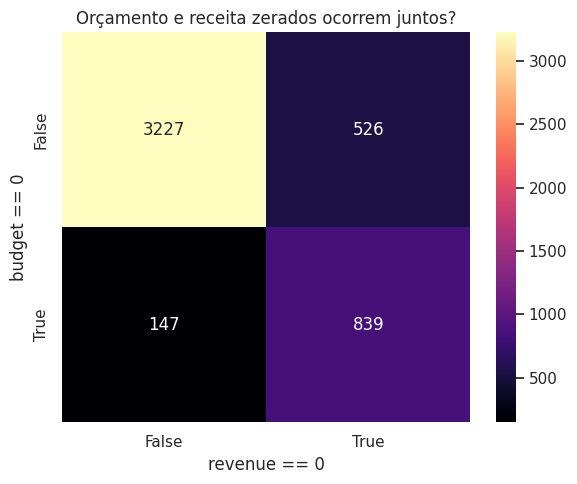

In [52]:
orcamento_zero = df["budget"] == 0
receita_zero = df["revenue"] == 0

tabela_contingencia = pd.crosstab(orcamento_zero, receita_zero,
            rownames=["budget == 0"], colnames=["revenue == 0"])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title("Orçamento e receita zerados ocorrem juntos?")
plt.tight_layout()
plt.show()

Dos filmes com budget == 0, a maioria também tem revenue == 0 (co-ocorrência forte, não aleatória) — indício de que é um subconjunto sistemático de filmes sem dados financeiros divulgados (provavelmente produções menores/indies), não uma falha aleatória de coleta.

In [53]:
df["orcamento_informado"] = df["budget"] > 0
df["receita_informada"] = df["revenue"] > 0

Como é ~20% das linhas, dropar tudo seria custoso demais — a decisão é manter as linhas e usar os flags acima pra excluir só quando a análise específica envolver budget/revenue.

#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**

Duas famílias de ausência aparecem no dataset:

- `overview`, `release_date`, `runtime`: dados administrativos/de catalogação, sem relação óbvia com o conteúdo do filme (já removidos, poucas linhas).
- `budget` e `revenue` (registrados como 0 quando não informados): dados financeiros que dependem de divulgação pública — estúdios grandes costumam divulgar essas cifras, produções menores/independentes geralmente não.

O crosstab acima mostra que a maioria dos filmes com `budget == 0` também tem `revenue == 0` — confirma o padrão sistemático, não aleatório.

**Classificação (MCAR/MAR/MNAR)**

- Se a ausência depende de algo externo ao valor (política de divulgação do estúdio, porte da produção) → **MAR**.
- Se a ausência depende do próprio valor (só bilheterias muito baixas ficam escondidas) → **MNAR**.

Produções menores tendem a ter cifras menores *e* a não divulgar — as duas explicações se misturam, então não dá pra decidir com certeza só olhando os dados. Por isso a decisão foi conservadora: manter as linhas e só sinalizar com `orcamento_informado`/`receita_informada`, em vez de descartar.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai orientar as decisões de tratamento de outliers na próxima seção.

In [54]:
VARS_QUANT = ["budget", "revenue", "popularity", "runtime", "vote_average", "vote_count"]
VARS_QUALI = ["original_language", "status"]

### Tabela descritiva, com assimetria e curtose

In [55]:
desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
budget,29432212.92,15000000.00,40858432.28,0.00,380000000.00,2.42,7.56
revenue,83371562.27,20000000.00,163670573.34,0.00,2787965087.00,4.42,32.77
popularity,21.78,13.29,31.93,0.00,875.58,9.72,191.40
runtime,107.28,104.00,21.98,0.00,338.00,1.02,8.97
vote_average,6.17,6.20,0.98,0.00,10.00,-0.70,1.84
vote_count,699.54,242.00,1240.27,1.00,13752.00,3.80,19.68


**Discussão:** olhando a tabela, `budget`, `revenue`, `popularity` e `vote_count` têm skewness alto (>1) e kurtosis alto — cauda pesada à direita. Isso é coerente com o esperado em dados de bilheteria/popularidade: a maioria dos filmes tem valores modestos, e um punhado de blockbusters puxa a cauda. Já `vote_average` tem skewness leve e negativo (-0,70) e kurtosis próxima de 0 (1,84), formato mais próximo do normal — faz sentido, já que nota é limitada entre 0 e 10 e tende a se concentrar num valor "típico".

### Distribuições de dados

Onde fizer sentido, comparamos "Mal avaliado" (rosa) vs. "Bem avaliado" (roxo) — convenção de cor mantida até a análise bivariada.[texto do link]

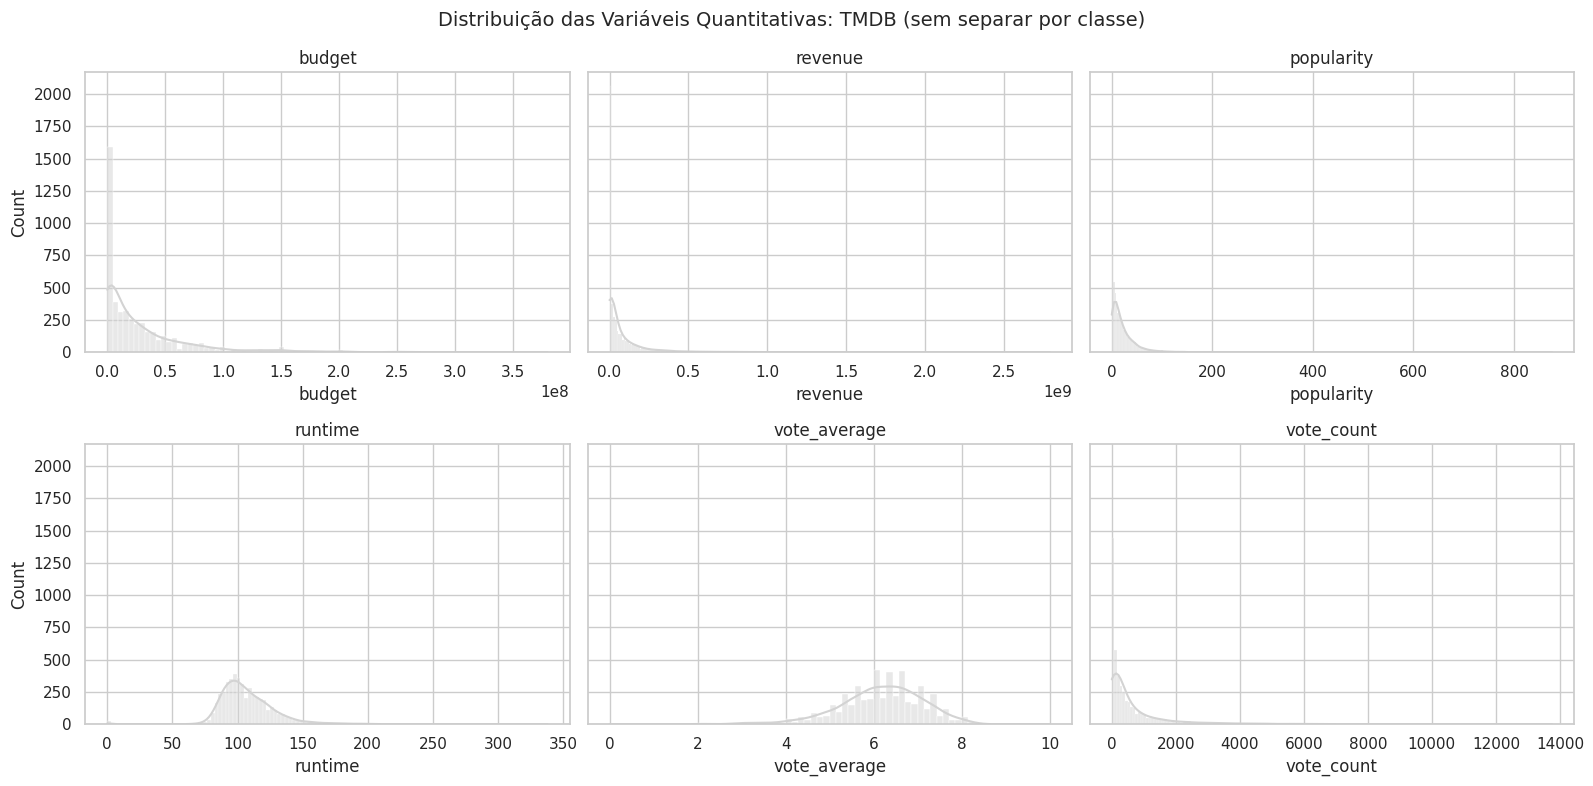

In [56]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Distribuição das Variáveis Quantitativas: TMDB (sem separar por classe)", fontsize=14)
plt.tight_layout()
plt.show()

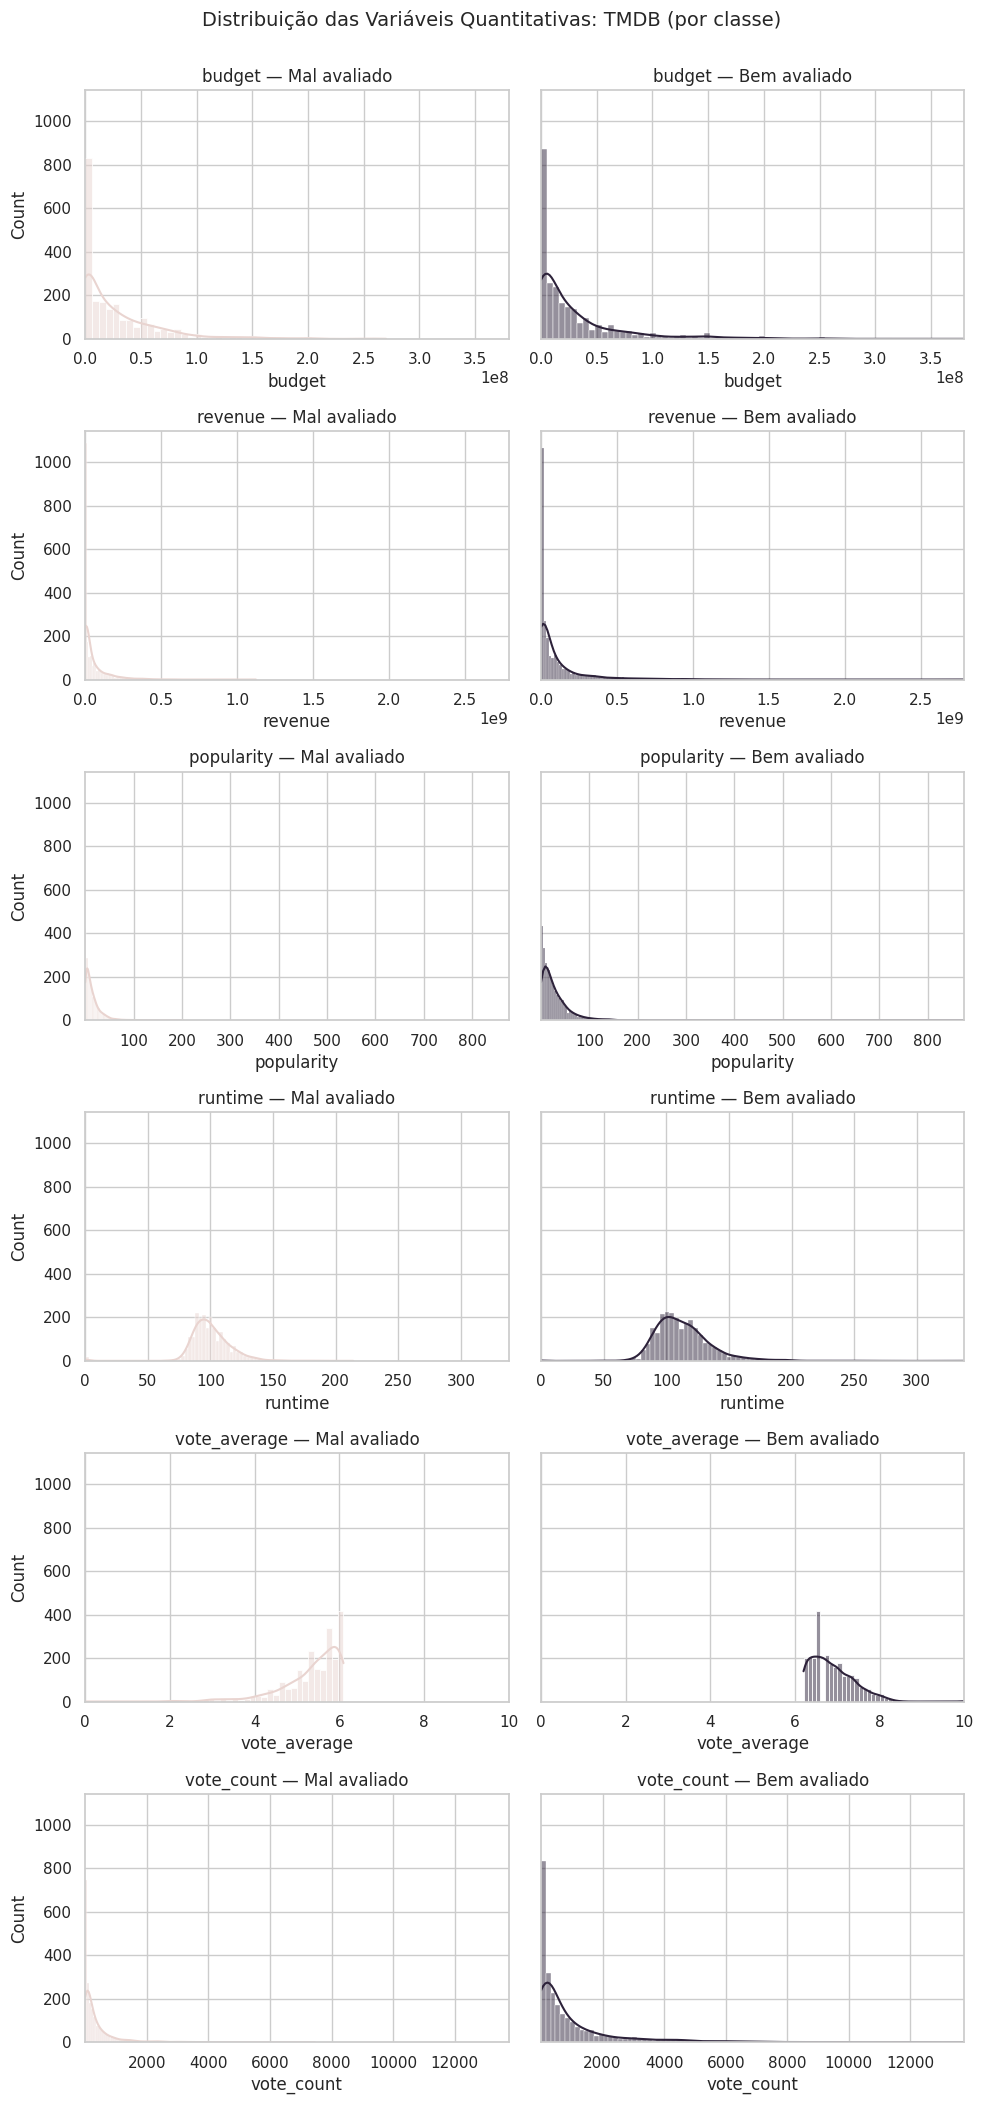

In [57]:
fig, axes = plt.subplots(len(VARS_QUANT), 2, figsize=(10, 3.5 * len(VARS_QUANT)), sharey=True)

for i, col in enumerate(VARS_QUANT):
    lim = (df[col].min(), df[col].max())
    for j, (classe, cor) in enumerate([("Mal avaliado", COR_CONTEXTO), ("Bem avaliado", COR_DESTAQUE)]):
        subset = df[df["avaliacao"] == classe]
        sns.histplot(data=subset, x=col, kde=True, color=cor, ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")

fig.suptitle("Distribuição das Variáveis Quantitativas: TMDB (por classe)", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

**Discussão:** comparando os painéis por classe, popularity, revenue e vote_count aparecem claramente deslocadas: no grupo "Mal avaliado" a massa fica praticamente toda colada em zero, com o pico bem mais alto ali e caindo quase a zero logo em seguida; no grupo "Bem avaliado" o pico inicial continua existindo, mas a cauda à direita é visivelmente mais pesada, há barras se espalhando por valores bem mais altos nas três variáveis (em revenue e vote_count, por exemplo, dá pra ver barras claramente visíveis bem mais longe do zero no painel "Bem avaliado" do que no "Mal avaliado"). Isso é coerente com o Mann-Whitney que roda mais à frente, que aponta diferença estatisticamente significativa justamente nessas três.

budget é o caso oposto: as duas classes têm formato quase idêntico, pico colado em zero e cauda longa parecida em ambas, sem deslocamento visível, o que já antecipa budget ser a única variável não significativa no teste bivariado (p≈0,18/0,22). runtime também fica bastante sobreposto entre as classes, com o mesmo formato aproximadamente unimodal em torno de 90-110 minutos; só dá pra notar o grupo "Bem avaliado" se espalhando um pouco mais para durações maiores. Já vote_average é um caso à parte: como o próprio alvo avaliacao foi criado a partir da mediana dessa variável, os dois painéis aparecem completamente separados, sem sobreposição nenhuma, com o corte exatamente na mediana (~6).

#### Testes de Aderência

*Será que a nota (`vote_average`) segue uma distribuição normal?*

O Shapiro-Wilk é o teste de aderência mais usado pra normalidade, junto com o QQ-Plot como visualização de apoio.

In [58]:
stat_sw, p_valor_sw = stats.shapiro(df["vote_average"].dropna())
print(f"Shapiro-Wilk — vote_average: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

Shapiro-Wilk — vote_average: estatística=0.9723, p-valor=2.467e-29
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


### QQ-Plot — Nota (vote_average)

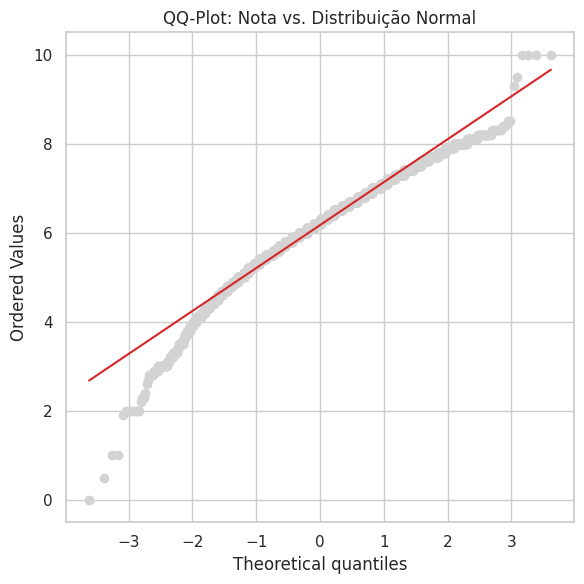

In [59]:
fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["vote_average"].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: Nota vs. Distribuição Normal")
plt.tight_layout()
plt.show()

**Como ler:** se os pontos (roxo) seguissem a reta vermelha de perto, a variável seguiria uma normal. Pontos que se afastam da reta nas pontas indicam cauda mais pesada ou mais leve que a normal.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** amostras pequenas têm menos poder estatístico e tendem a *não* rejeitar a normalidade mesmo quando os dados não são normais; amostras muito grandes deixam o teste sensível demais, rejeitando por desvios triviais. Com n≈4.700, é uma amostra grande — vale considerar isso ao interpretar o p-valor junto com o skewness e o QQ-Plot, não isoladamente.
- **Como afirmar o resultado:** se o teste **rejeita** H0 (p < 0.05), a afirmação correta é "há evidência estatística **contra** a normalidade". "Não podemos garantir normalidade" cabe no caso oposto (quando o teste **não** rejeita).

In [60]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna().sample(min(5000, len(df)), random_state=42))
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
budget,0.7205,0.0,True
revenue,0.5408,0.0,True
popularity,0.5263,0.0,True
runtime,0.8792,0.0,True
vote_average,0.9723,0.0,True
vote_count,0.5682,0.0,True


**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, mostra a proporção acumulada de observações menores ou iguais àquele valor. Útil pra comparar duas distribuições lado a lado. Vamos ilustrar com `vote_average`.

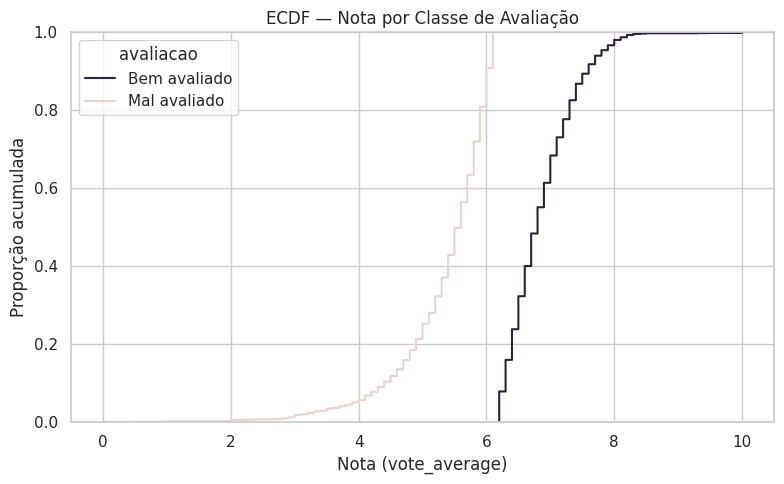

In [61]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="vote_average", hue="avaliacao",
             palette={"Mal avaliado": COR_CONTEXTO, "Bem avaliado": COR_DESTAQUE})
plt.title("ECDF — Nota por Classe de Avaliação")
plt.xlabel("Nota (vote_average)")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva diz "que fração dos filmes desse grupo tem nota até aqui". Onde as duas curvas se distanciam mais, ali está a faixa onde os dois grupos mais diferem.

### Métricas de Tendêncial Central

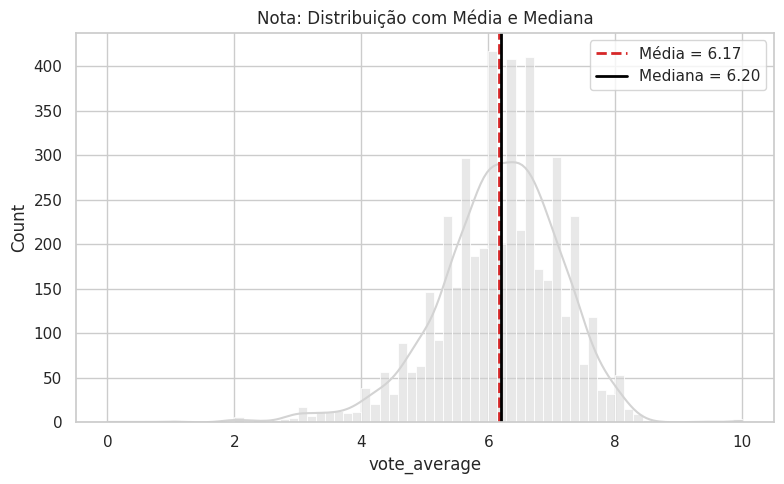

In [62]:
media_nota = df["vote_average"].mean()
mediana_nota_calc = df["vote_average"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="vote_average", kde=True, color=COR_NEUTRA)
plt.axvline(media_nota, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_nota:.2f}")
plt.axvline(mediana_nota_calc, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_nota_calc:.2f}")
plt.title("Nota: Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão

In [63]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)

,var,std,IQR
budget,1.669411e+15,4.085843e+07,39000000.00
revenue,2.678806e+16,1.636706e+08,94376313.00
popularity,1.019740e+03,3.193000e+01,23.69
runtime,4.829900e+02,2.198000e+01,24.00
vote_average,9.500000e-01,9.800000e-01,1.20
vote_count,1.538275e+06,1.240270e+03,692.50


**Discussão:** a caixa (IQR) de `revenue` e `popularity` é nitidamente mais alta (maior amplitude) no grupo "Bem avaliado" do que no "Mal avaliado" — reforça o que já apareceu na tabela de dispersão (IQR de `revenue` ≈117M vs. ≈68M no grupo mal avaliado). Isso indica que filmes bem avaliados têm uma faixa de receita e popularidade bem mais ampla, puxada por alguns grandes sucessos. Já `budget` e `runtime` têm caixas de tamanho parecido entre as duas classes — sozinhas, discriminam menos bem "Bem avaliado" de "Mal avaliado".

### Boxplot e violin plot por classe

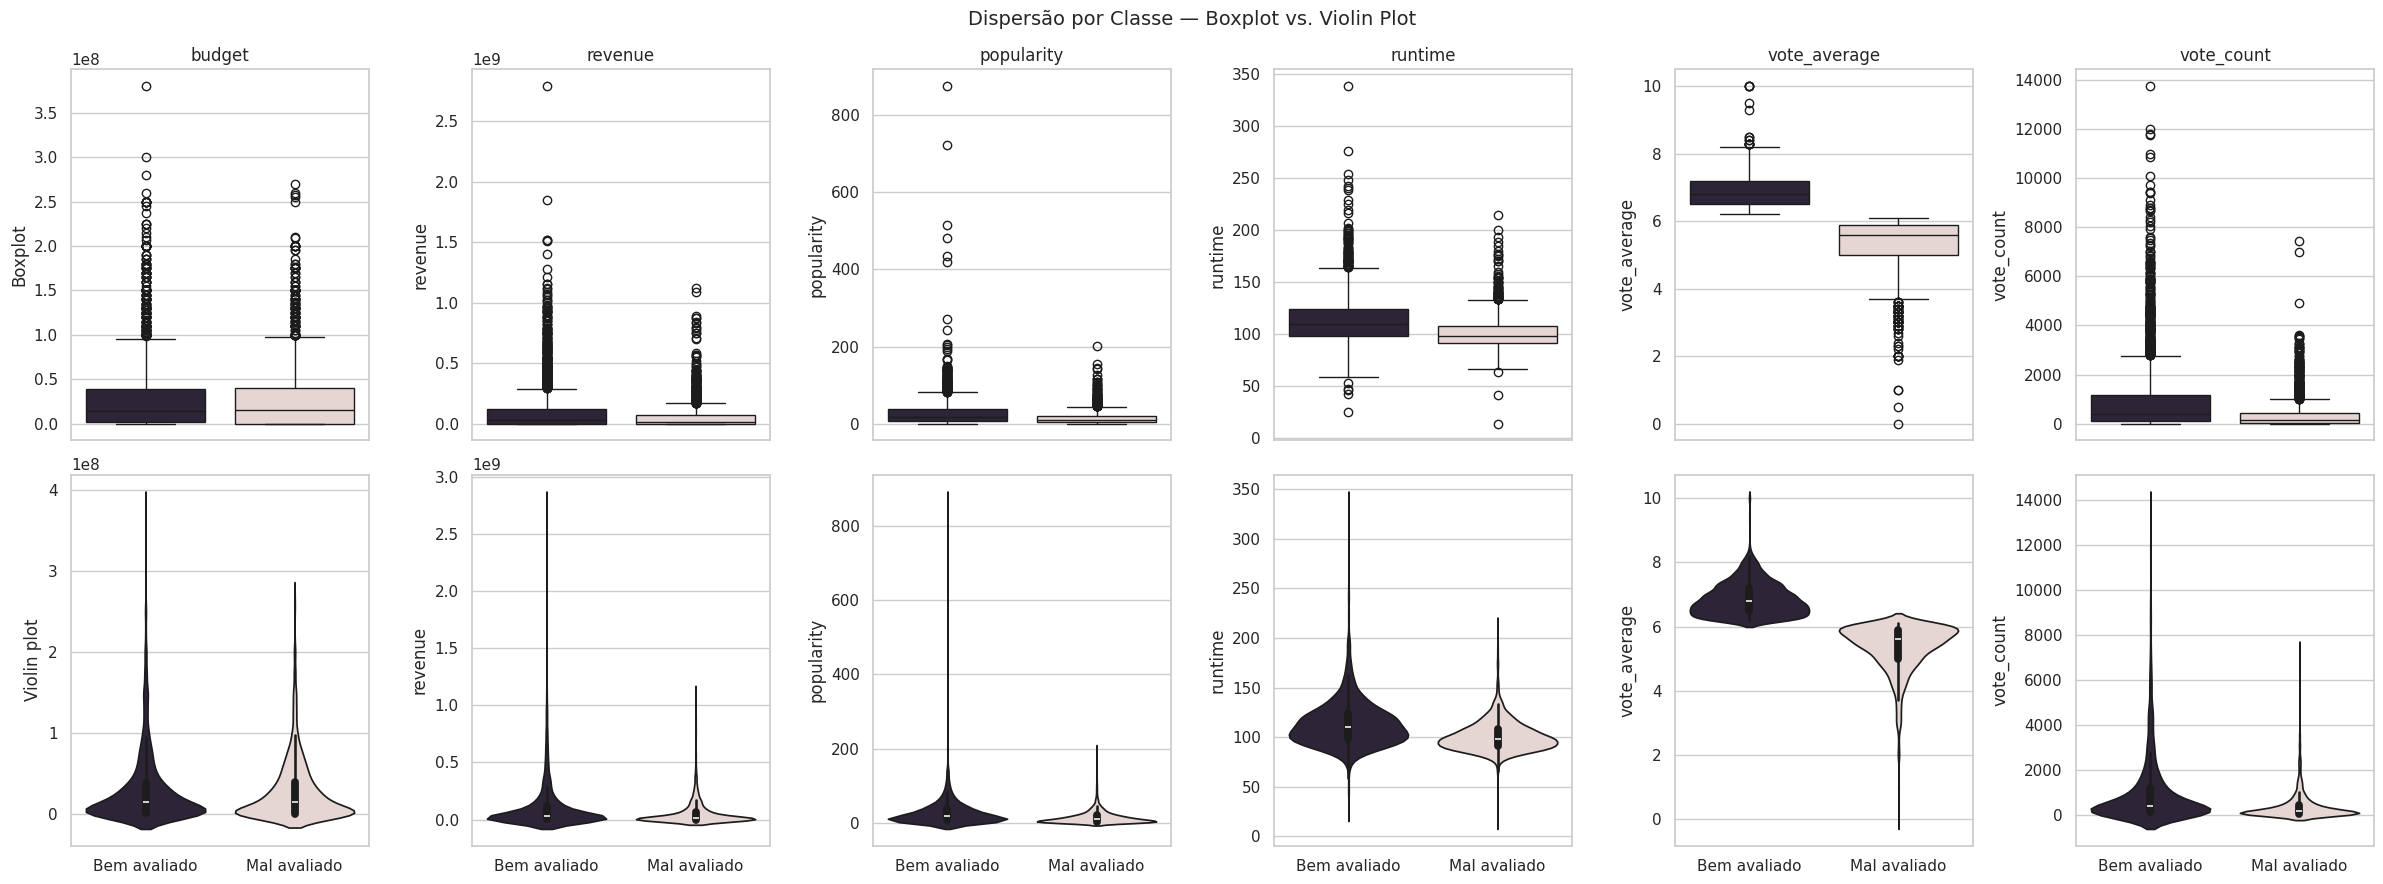

In [87]:
palette_classe = {"Mal avaliado": COR_CONTEXTO, "Bem avaliado": COR_DESTAQUE}

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 9), sharex="col")

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="avaliacao", y=col, hue="avaliacao",
                palette=palette_classe, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, x="avaliacao", y=col, hue="avaliacao",
                    palette=palette_classe, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Classe — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

## 4. Tratamento de Outliers

Os dados ausentes já foram tratados na Seção 2. Agora, com o retrato estatístico "antes" da Seção 3, vamos decidir como tratar os outliers das variáveis quantitativas. Depois do tratamento, rodamos a estatística descritiva mais uma vez ("depois") pra fechar o ciclo iterativo.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [64]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {"limite_inferior": round(lim_inf, 2),
                             "limite_superior": round(lim_sup, 2), "n_outliers": n_outliers}

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
budget,-5.750000e+07,9.850000e+07,321.0
revenue,-1.415645e+08,2.359408e+08,460.0
popularity,-3.056000e+01,6.421000e+01,271.0
runtime,5.800000e+01,1.540000e+02,169.0
vote_average,3.800000e+00,8.600000e+00,94.0
vote_count,-9.807500e+02,1.789250e+03,496.0


### Visualizando os Outliers

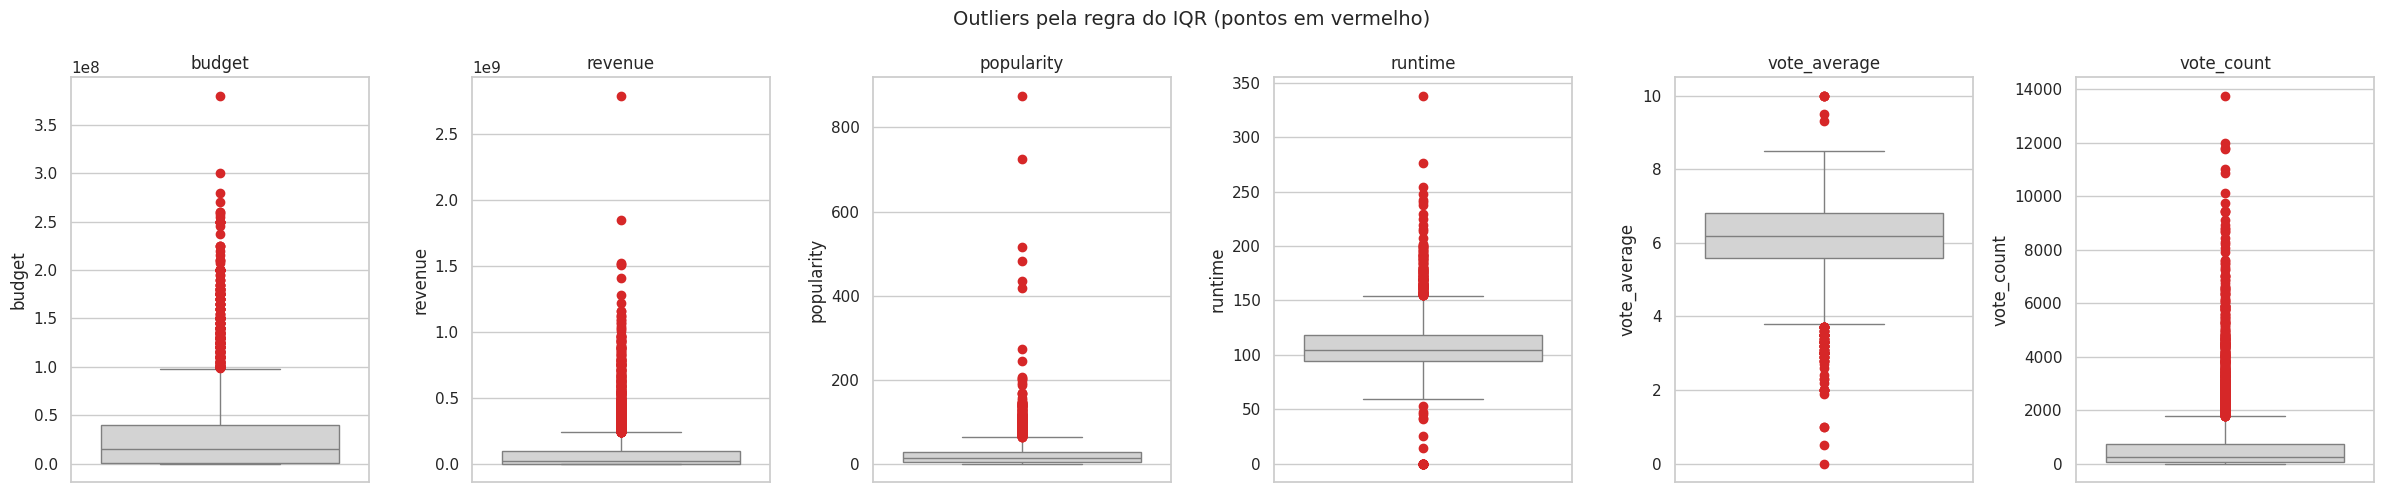

In [65]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))
for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)
fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Discussão:** o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Investigando os outliers do IQR: os valores altos de `budget`, `revenue`, `popularity` e `vote_count` (ex: *Avatar*, com receita de ~2,8 bilhões) são **estatísticos/legítimos** — blockbusters reais puxando a cauda, não erro de coleta. Já 23 filmes com `runtime == 0` violam uma regra física óbvia (nenhum longa dura zero minutos) — **erro de domínio/dado**. E olhando de perto, tem filmes com `revenue` ou `budget` positivos mas ridiculamente baixos (ex: receita de $5, $7, $11) — números implausíveis pra qualquer bilheteria real, também **erro de dados**, provavelmente valores truncados ou mal digitados na fonte.

In [66]:
df_antes = df.copy()

runtime_zero = df["runtime"] == 0
print(f"Filmes com runtime = 0 (erro de dado): {runtime_zero.sum()}")
df.loc[runtime_zero, "runtime"] = np.nan

valor_implausivel_budget = (df["budget"] > 0) & (df["budget"] < 1000)
valor_implausivel_revenue = (df["revenue"] > 0) & (df["revenue"] < 1000)
print(f"budget implausível (<1000, provável erro): {valor_implausivel_budget.sum()}")
print(f"revenue implausível (<1000, provável erro): {valor_implausivel_revenue.sum()}")

df.loc[valor_implausivel_budget, "orcamento_informado"] = False
df.loc[valor_implausivel_revenue, "receita_informada"] = False

Filmes com runtime = 0 (erro de dado): 23
budget implausível (<1000, provável erro): 28
revenue implausível (<1000, provável erro): 22


### Decidindo o Tratamento dos Outliers

Os erros de dados (`runtime == 0` e valores financeiros implausíveis) já foram corrigidos acima. Os outliers restantes — valores altos de `budget`, `revenue`, `popularity` e `vote_count` — são estatísticos e legítimos (filmes reais de grande sucesso), então vamos **manter**. Como demonstração de uma alternativa (útil se a assimetria atrapalhar algum teste ou modelo mais adiante), vamos ilustrar a transformação logarítmica em `revenue`.

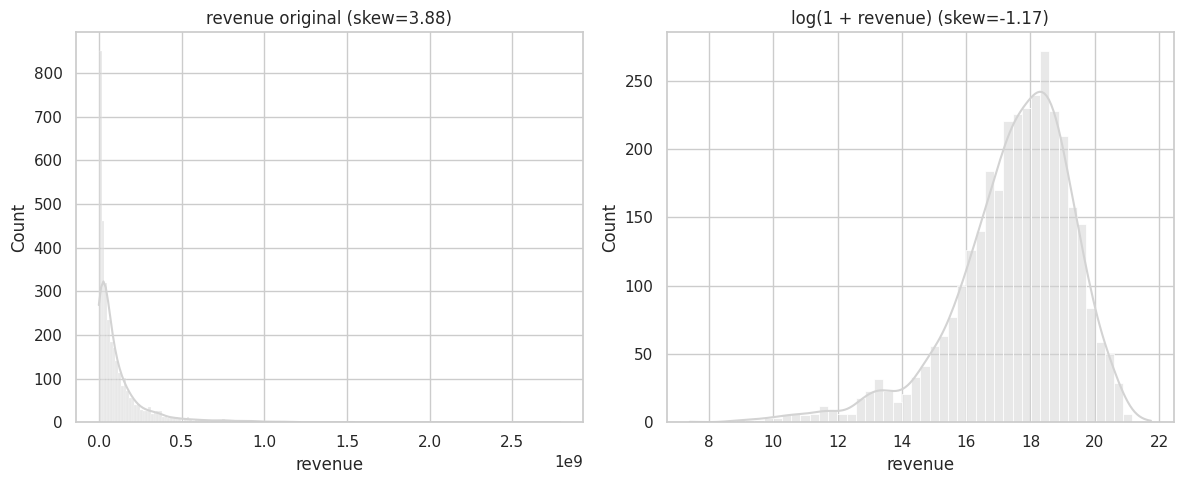

In [67]:
revenue_valido = df.loc[df["receita_informada"], "revenue"]
revenue_log = np.log1p(revenue_valido)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(revenue_valido, kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"revenue original (skew={revenue_valido.skew():.2f})")

sns.histplot(revenue_log, kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + revenue) (skew={revenue_log.skew():.2f})")
plt.tight_layout()
plt.show()

**Discussão:** o log reduziu bastante o skew (de 3,88 pra -1,17), mas passou de positivo pra levemente negativo — não ficou perfeitamente simétrico. Isso sugere que `revenue` não segue exatamente uma lognormal; ainda há uma concentração de filmes com receita bem alta em relação à mediana mesmo depois do log. Mantivemos `revenue` original nas próximas seções; `revenue_log` fica só como demonstração.

## 5. Estatística Descritiva pt 2

Fechando o ciclo: corrigimos os erros de dados (`runtime`, valores financeiros implausíveis) e decidimos manter os demais outliers. Rodamos a mesma bateria de estatísticas da Seção 3 pra comparar com o "antes".

In [68]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
budget,29432212.92,15000000.00,40858432.28,0.00,380000000.00,2.42,7.56
revenue,83371562.27,20000000.00,163670573.34,0.00,2787965087.00,4.42,32.77
popularity,21.78,13.29,31.93,0.00,875.58,9.72,191.40
runtime,107.81,104.00,20.71,14.00,338.00,1.83,8.55
vote_average,6.17,6.20,0.98,0.00,10.00,-0.70,1.84
vote_count,699.54,242.00,1240.27,1.00,13752.00,3.80,19.68


### Comparando "antes"x "depois""



In [69]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
budget,2.422,2.422,7.563,7.563,0.000,0.000
revenue,4.419,4.419,32.768,32.768,0.000,0.000
popularity,9.722,9.722,191.405,191.405,0.000,0.000
runtime,1.019,1.826,8.972,8.549,0.807,-0.423
vote_average,-0.702,-0.702,1.838,1.838,0.000,0.000
vote_count,3.802,3.802,19.685,19.685,0.000,0.000


**Discussão:** `budget`, `revenue`, `popularity`, `vote_average` e `vote_count` ficaram idênticos — fazia sentido, já que só alteramos flags, não os valores numéricos dessas colunas. `runtime` foi o único que mudou de verdade: ao remover os 23 filmes com duração zerada (~0,5% das linhas), o skewness **subiu** de 1,02 pra 1,83, em vez de cair. Isso acontece porque os zeros ficavam isolados na ponta esquerda da distribuição; ao removê-los, o lado direito (filmes muito longos, como minisséries de +250 min) passa a pesar proporcionalmente mais no cálculo. Ou seja: corrigir um erro de dado nem sempre reduz a assimetria — depende de onde o erro estava.

**A nota ainda rejeita normalidade?**

Vamos rodar o mesmo Shapiro-Wilk da Seção 3, agora nos dados tratados.

In [70]:
stat_sw_depois, p_valor_sw_depois = stats.shapiro(df["vote_average"].dropna())
print(f"Shapiro-Wilk (antes)  — vote_average: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print(f"Shapiro-Wilk (depois) — vote_average: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}")

Shapiro-Wilk (antes)  — vote_average: estatística=0.9723, p-valor=2.467e-29
Shapiro-Wilk (depois) — vote_average: estatística=0.9723, p-valor=2.467e-29


**Visualizando antes x depois, lado a lado**

Vamos sobrepor as distribuições de `runtime` (a variável que foi corrigida) e `vote_average` (que não foi tocada), comparando a versão original (`df_antes`) com a tratada (`df`).

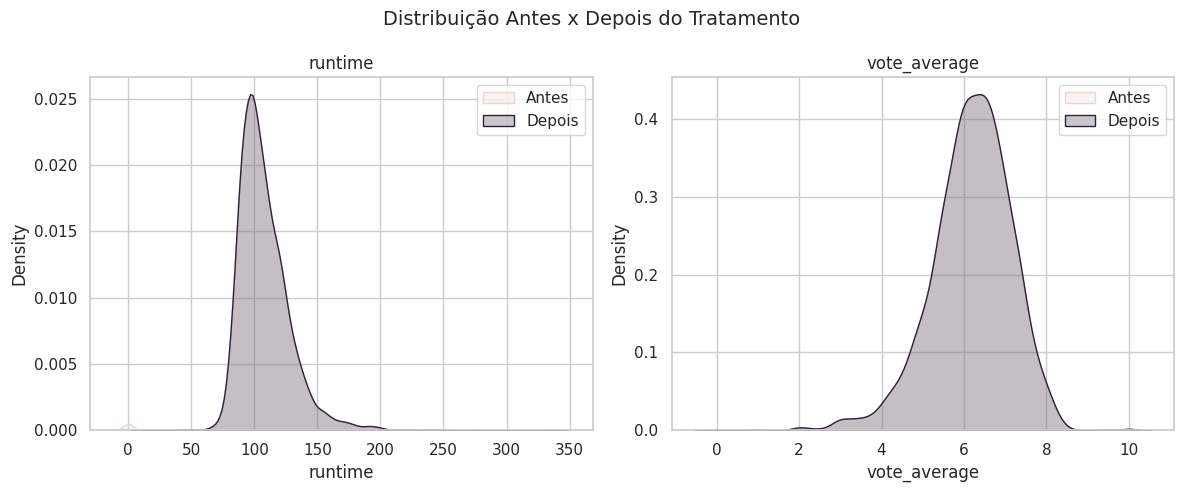

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, col in zip(axes, ["runtime", "vote_average"]):
    sns.kdeplot(df_antes[col], color=COR_CONTEXTO, fill=True, label="Antes", ax=ax)
    sns.kdeplot(df[col], color=COR_DESTAQUE, fill=True, label="Depois", ax=ax)
    ax.set_title(col)
    ax.legend()
fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)
plt.tight_layout()
plt.show()

**Discussão:** a curva de `runtime` muda visivelmente perto do zero (o pico artificial dos 23 filmes com duração 0 desaparece), enquanto `vote_average` fica praticamente idêntica antes e depois — como esperado, já que essa variável não fez parte do tratamento. Diferente do exemplo da aula (onde quase nada mudou porque o volume de ausentes era pequeno e nenhum outlier foi alterado), aqui a comparação "antes x depois" mostra exatamente o que deveria: mudança onde houve correção, estabilidade onde não houve.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [72]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts().head(15)
    freq_rel = df[col].value_counts(normalize=True).round(3).head(15)
    print(f"\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))


--- original_language ---
                   absoluta  relativa
original_language                    
en                     4448     0.939
fr                       69     0.015
es                       32     0.007
zh                       27     0.006
de                       26     0.005
hi                       18     0.004
ja                       16     0.003
it                       13     0.003
cn                       12     0.003
ru                       11     0.002
ko                       11     0.002
pt                        8     0.002
da                        7     0.001
sv                        5     0.001
fa                        4     0.001

--- status ---
                 absoluta  relativa
status                             
Released             4732     0.999
Rumored                 4     0.001
Post Production         3     0.001


#### Visualizando as frequências

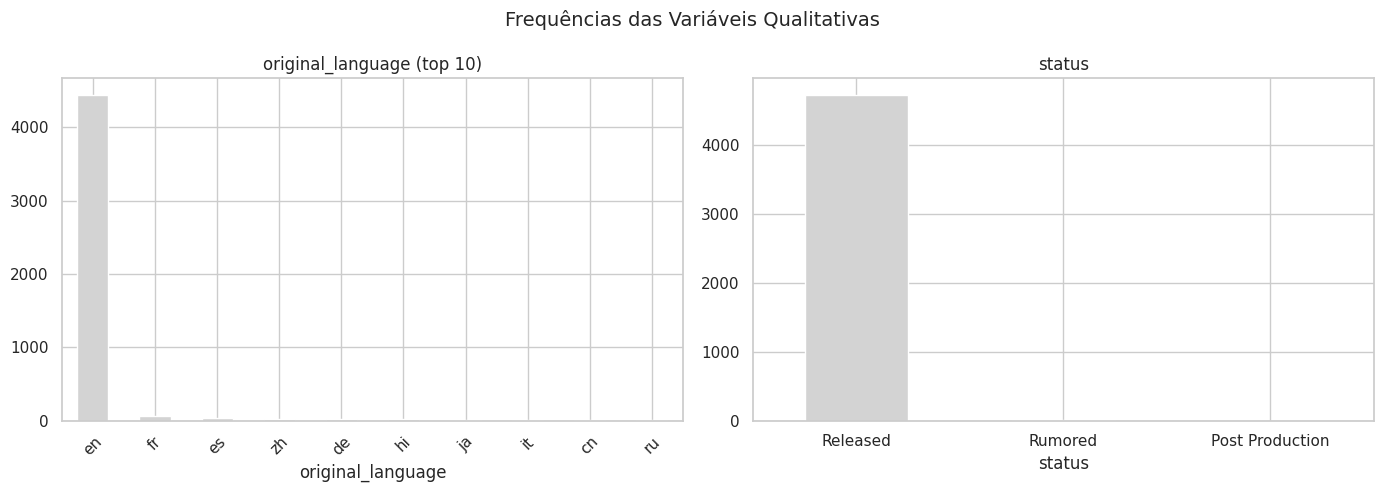

In [73]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

top10_idioma = df["original_language"].value_counts().head(10)
top10_idioma.plot(kind="bar", color=COR_NEUTRA, ax=axes[0])
axes[0].set_title("original_language (top 10)")
axes[0].tick_params(axis="x", rotation=45)

df["status"].value_counts().plot(kind="bar", color=COR_NEUTRA, ax=axes[1])
axes[1].set_title("status")
axes[1].tick_params(axis="x", rotation=0)

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

**Discussão:** as duas são fortemente desbalanceadas. `original_language` tem 36 categorias, mas `en` sozinho responde por 4.448 dos 4.739 filmes (~94%) — o resto se divide em categorias pequenas (`fr` com 69, `es` com 32, etc.). `status` é ainda mais extremo: 4.732 filmes são `Released`, sobrando só 4 `Rumored` e 3 `Post Production`. Isso já sinaliza que `status` provavelmente não vai render cruzamentos estatísticos confiáveis mais adiante — os grupos minoritários são pequenos demais.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Apliquei as duas em todas as qualitativas, incluindo o próprio alvo `avaliacao`.

In [74]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({"n_classes": n_classes, "razao_desbalanceamento": round(razao, 2),
                       "entropia_normalizada": round(ent_normalizada, 3)})

vars_para_checar = VARS_QUALI + ["avaliacao"]
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
original_language,36.0,4448.00,0.112
status,3.0,1577.33,0.011
avaliacao,2.0,1.17,0.996


**Discussão:** `original_language` (entropia 0,11) e `status` (entropia 0,01) estão quase totalmente desbalanceados — próximos de 0, uma categoria domina quase tudo. Já o alvo `avaliacao` tem entropia 0,996 (quase 1 = perfeitamente balanceado), fruto do corte pela mediana. Isso é bom: o alvo balanceado não vai distorcer os cruzamentos bivariados a seguir, mas `status` provavelmente é qualitativa demais pra qualquer teste que exija grupos com tamanho mínimo razoável.

### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si e com o alvo 'avaliação'.

#### Quantitativa x Quantitativa - Correlação

Como nenhuma das variáveis passou no Shapiro-Wilk (Seção 3), a métrica mais adequada aqui é a **Spearman** — não exige normalidade e captura relação monotônica (não só linear).

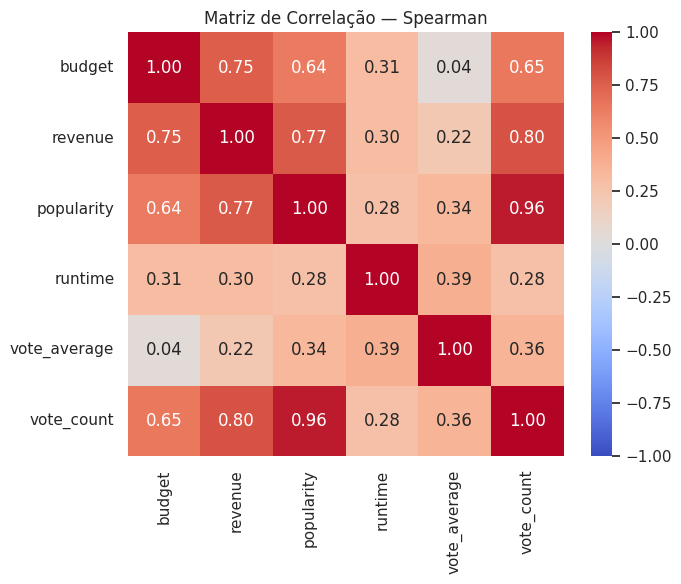

In [75]:
corr_spearman = df[VARS_QUANT].corr(method="spearman")

plt.figure(figsize=(7, 6))
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação — Spearman")
plt.tight_layout()
plt.show()

**Discussão:** `popularity` x `vote_count` tem a correlação mais forte (0,96) — chama atenção por sugerir redundância entre variáveis, já que ambas medem essencialmente "quanto o filme foi visto/comentado". `budget` x `vote_average` é a mais fraca (0,04) — orçamento praticamente não se relaciona com nota.

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhi `budget` x `revenue` por um motivo de domínio: existe uma relação de negócio esperada entre quanto se investe em um filme e quanto ele arrecada, o que torna esse par um bom candidato pra visualizar uma tendência real.

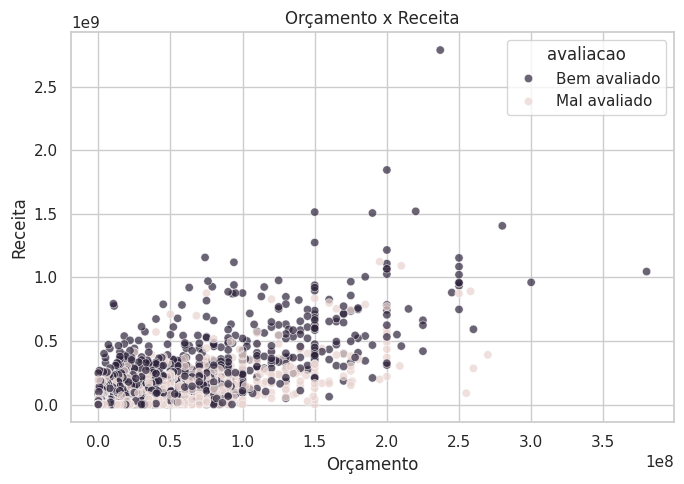

In [76]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="budget", y="revenue", hue="avaliacao",
                palette={"Mal avaliado": COR_CONTEXTO, "Bem avaliado": COR_DESTAQUE}, alpha=0.7)
plt.title("Orçamento x Receita")
plt.xlabel("Orçamento")
plt.ylabel("Receita")
plt.tight_layout()
plt.show()

**Discussão:** a correlação geral (Spearman) entre `budget` e `revenue` é 0,75 — forte, como esperado.

#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada listamos **T-Test** (2 grupos) e **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo.

Já vimos na Seção 3 (tabela generalizada do Shapiro-Wilk) que **nenhuma** das nossas quantitativas passou nesse teste. Isso significa que, tecnicamente, deveríamos usar os equivalentes **não-paramétricos**: **Mann-Whitney U** no lugar do T-Test, e **Kruskal-Wallis** no lugar da ANOVA. Vamos calcular os dois lado a lado pra comparar, mas o resultado não-paramétrico é o que deveríamos reportar como principal.

In [77]:
resultados_comparacao = []
for col in VARS_QUANT:
    grupo_bem = df.loc[df["avaliacao"] == "Bem avaliado", col].dropna()
    grupo_mal = df.loc[df["avaliacao"] == "Mal avaliado", col].dropna()

    stat_t, p_t = stats.ttest_ind(grupo_bem, grupo_mal, equal_var=False)
    stat_u, p_u = stats.mannwhitneyu(grupo_bem, grupo_mal)

    resultados_comparacao.append({
        "variavel": col, "p_valor_ttest": round(p_t, 6), "p_valor_mannwhitney": round(p_u, 6),
        "concordam": (p_t < 0.05) == (p_u < 0.05),
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")

,p_valor_ttest,p_valor_mannwhitney,concordam
variavel,,,
budget,0.176275,0.215292,True
revenue,0.000000,0.000000,True
popularity,0.000000,0.000000,True
runtime,0.000000,0.000000,True
vote_average,0.000000,0.000000,True
vote_count,0.000000,0.000000,True


**Discussão:** os dois testes concordam em todas as 6 variáveis. Cinco (`revenue`, `popularity`, `runtime`, `vote_average`, `vote_count`) são estatisticamente significativas — diferem entre "Bem avaliado" e "Mal avaliado". Só `budget` não é significativa em nenhum dos dois testes (p≈0,18/0,22), reforçando o que já víamos nas medianas parecidas da Seção 3: orçamento sozinho não distingue as classes. Como nenhuma variável passou no Shapiro (Seção 3), o **Mann-Whitney** é o resultado que deveríamos reportar como principal.

**Nota:** mantivemos o T-test aqui só como contraste pedagógico.

*Exemplo com 3+ grupos — ANOVA x Kruskal-Wallis*

`original_language` tem 36 categorias, mas a maioria com poucos filmes. Filtrando só as 5 mais frequentes (`en`, `fr`, `es`, `zh`, `de`), calculamos a ANOVA (paramétrica) e o **Kruskal-Wallis** (não-paramétrico) lado a lado pra comparar `popularity` entre elas.

ANOVA          — popularity entre idiomas: estatística=4.960, p-valor=0.00054625
Kruskal-Wallis — popularity entre idiomas: estatística=41.557, p-valor=2.0613e-08


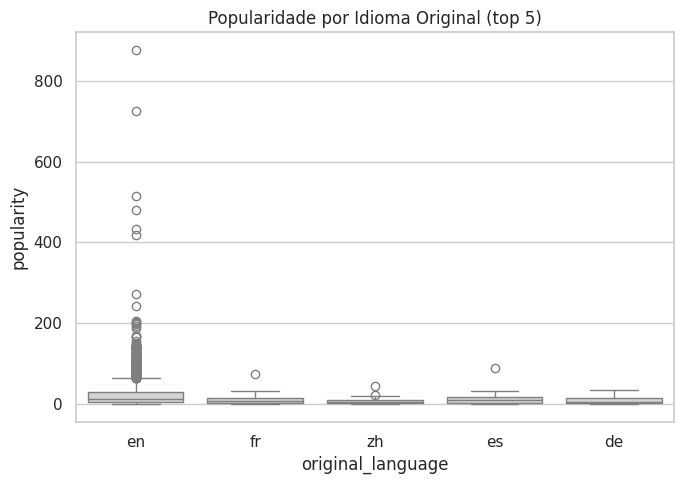

In [78]:
top5_idiomas = df["original_language"].value_counts().head(5).index.tolist()
sub_idiomas = df[df["original_language"].isin(top5_idiomas)]
grupos_idioma = [g["popularity"].values for _, g in sub_idiomas.groupby("original_language")]

stat_anova, p_anova = stats.f_oneway(*grupos_idioma)
stat_kw, p_kw = stats.kruskal(*grupos_idioma)

print(f"ANOVA          — popularity entre idiomas: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}")
print(f"Kruskal-Wallis — popularity entre idiomas: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}")

plt.figure(figsize=(7, 5))
sns.boxplot(data=sub_idiomas, x="original_language", y="popularity", color=COR_NEUTRA)
plt.title("Popularidade por Idioma Original (top 5)")
plt.tight_layout()
plt.show()

**Discussão:** os dois testes concordam — diferença estatisticamente significativa entre idiomas (p<0,001 nos dois). A mediana de popularidade em `en` é 14,0, bem acima de `es` (9,4), `fr` (8,2), `zh` (5,3) e `de` (5,2). Como sabemos que `popularity` não é normal (Seção 3), o **Kruskal-Wallis** é o resultado principal — a ANOVA fica só como contraste.

#### Quantitativa x Qualitativa

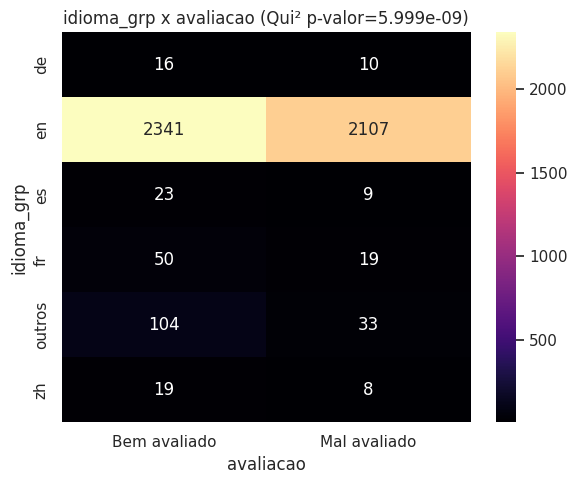

In [79]:
top5_idiomas = df["original_language"].value_counts().head(5).index.tolist()
df["idioma_grp"] = np.where(df["original_language"].isin(top5_idiomas), df["original_language"], "outros")

contingencia_idioma = pd.crosstab(df["idioma_grp"], df["avaliacao"])
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_idioma)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(contingencia_idioma, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"idioma_grp x avaliacao (Qui² p-valor={p_chi2:.4g})")
plt.tight_layout()
plt.show()

**Discussão:** o Qui-Quadrado indica associação estatisticamente significativa entre `idioma_grp` e `avaliacao` (p≈6e-9, todas as frequências esperadas acima de 5, então o teste é válido aqui). Olhando as proporções: filmes em inglês têm só 52,6% de "Bem avaliado", enquanto todos os outros grupos de idioma ficam entre 61,5% e 75,9%. Isso não significa que filmes em outro idioma são "melhores" — é mais provável que reflita um viés de amostragem: o TMDB tem um catálogo enorme de produções médianas em inglês, enquanto os filmes em outros idiomas que entram na base tendem a ser os que ganharam alguma visibilidade internacional (já uma seleção de qualidade).

#### Avaliação de Fairness

#### Avaliação por Subgrupo

Olhar o desbalanceamento da base inteira é só metade da história. Uma pergunta recorrente em EDA antes de qualquer modelagem é: será que a proporção de "Bem avaliado" se comporta igual em diferentes subgrupos que, a princípio, não deveriam determinar a qualidade de um filme — como década de lançamento ou faixa de orçamento? Se não, isso pode refletir um viés real da base (ex: filmes antigos que sobrevivem no catálogo tendem a ser só os "clássicos") ou um padrão genuíno do mercado — de qualquer forma, vale mapear antes de qualquer modelagem.

Desbalanceamento — década:
n_classes                  6.000
razao_desbalanceamento    18.660
entropia_normalizada       0.769
dtype: float64

Desbalanceamento — faixa de orçamento:
n_classes                 3.000
razao_desbalanceamento    1.840
entropia_normalizada      0.968
dtype: float64


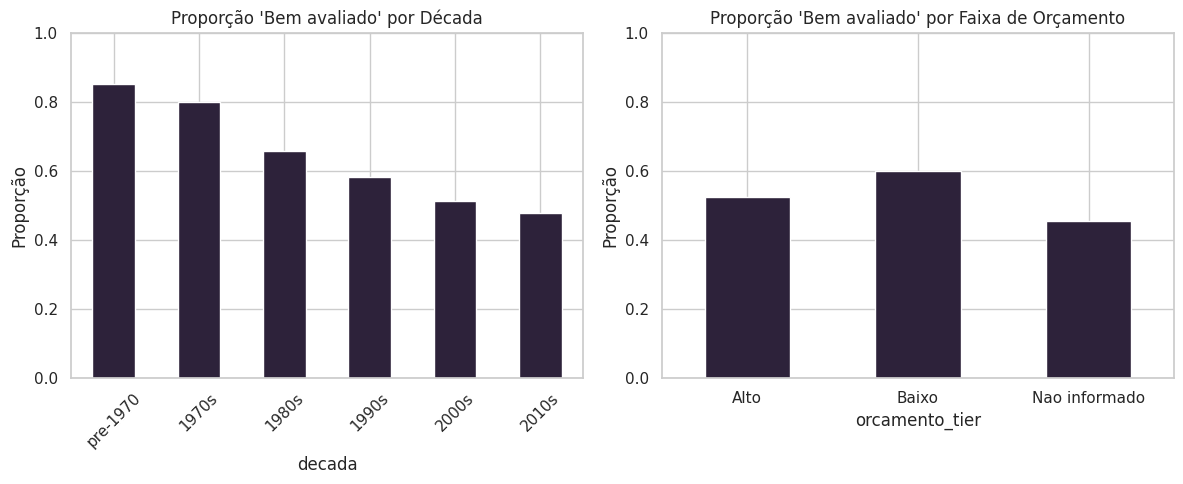

In [80]:
df["release_date"] = pd.to_datetime(df["release_date"])
ano = df["release_date"].dt.year
df["decada"] = np.where(ano < 1970, "pre-1970", (ano // 10 * 10).astype(str) + "s")

df["orcamento_tier"] = np.where(~df["orcamento_informado"], "Nao informado",
                          np.where(df["budget"] < df.loc[df.orcamento_informado, "budget"].median(), "Baixo", "Alto"))

print("Desbalanceamento — década:")
print(metrica_desbalanceamento(df["decada"]))
print("\nDesbalanceamento — faixa de orçamento:")
print(metrica_desbalanceamento(df["orcamento_tier"]))

prop_por_decada = pd.crosstab(df["decada"], df["avaliacao"], normalize="index").round(3)
prop_por_orcamento = pd.crosstab(df["orcamento_tier"], df["avaliacao"], normalize="index").round(3)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ordem_decadas = ["pre-1970", "1970s", "1980s", "1990s", "2000s", "2010s"]
prop_por_decada.loc[ordem_decadas, "Bem avaliado"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[0])
axes[0].set_title("Proporção 'Bem avaliado' por Década")
axes[0].set_ylabel("Proporção")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=45)

prop_por_orcamento["Bem avaliado"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[1])
axes[1].set_title("Proporção 'Bem avaliado' por Faixa de Orçamento")
axes[1].set_ylabel("Proporção")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

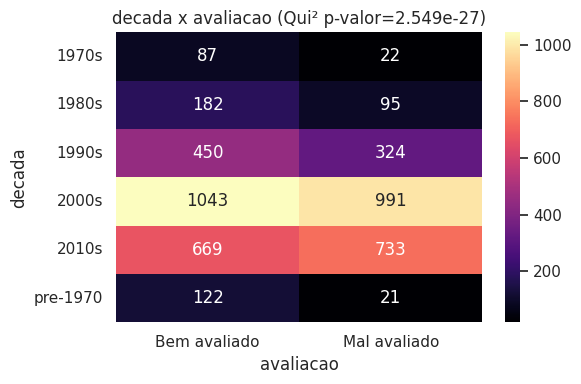

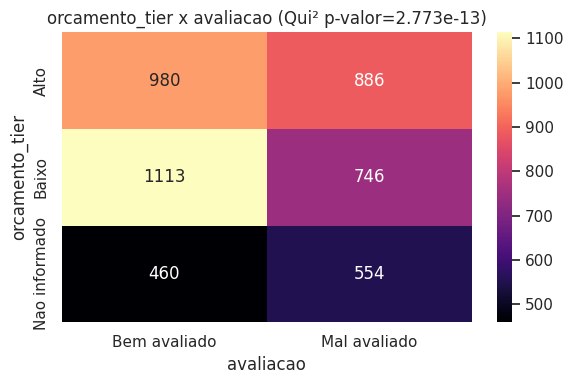

In [82]:
for atributo in ["decada", "orcamento_tier"]:
    contingencia = pd.crosstab(df[atributo], df["avaliacao"])
    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

    fig, ax = plt.subplots(figsize=(6, 4))
    sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title(f"{atributo} x avaliacao (Qui² p-valor={p_valor:.4g})")
    plt.tight_layout()
    plt.show()

**Discussão:** a proporção de "Bem avaliado" cai de forma quase monotônica com o tempo — de 85,3% nos filmes pré-1970 pra 47,7% nos filmes de 2010. Isso provavelmente não é porque "os filmes pioraram": é mais plausível que seja viés de sobrevivência — só os clássicos de décadas antigas continuam catalogados e sendo avaliados hoje, enquanto a leva de filmes recentes inclui muito mais produção "comum" ainda sem esse filtro do tempo. Já por faixa de orçamento, o padrão é o oposto do que se esperaria: filmes de orçamento **baixo** têm proporção de bem avaliados maior (59,9%) que os de orçamento **alto** (52,5%) — dinheiro não parece "comprar" nota.

#### Outliers bivariados

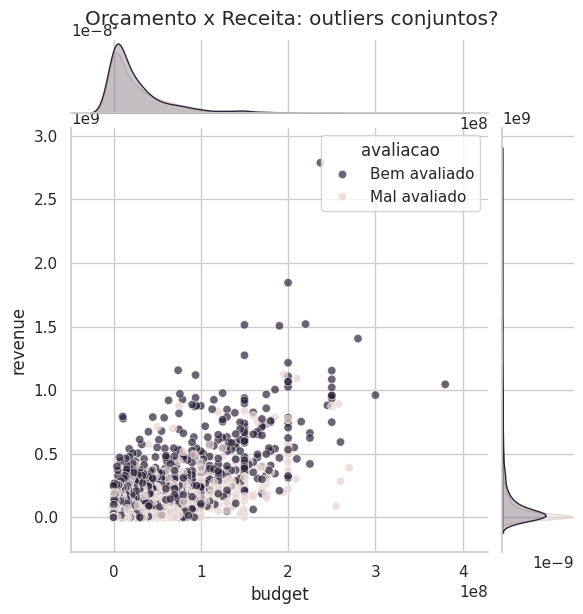

In [83]:
sns.jointplot(data=df, x="budget", y="revenue", hue="avaliacao",
              palette={"Mal avaliado": COR_CONTEXTO, "Bem avaliado": COR_DESTAQUE}, alpha=0.7, height=6)
plt.suptitle("Orçamento x Receita: outliers conjuntos?", y=1.02)
plt.show()

**Discussão:** sim — quase todos os pontos mais extremos aqui **não** apareciam como outliers nos histogramas univariados de `budget` ou `revenue` (Seção 3/4), porque cada valor sozinho é comum; é a **combinação** dos dois que é incomum. Do lado dos "flops": *The Adventurer: The Curse of the Midas Box* (orçamento de US$25M, receita de só US$6,4 mil) e *Foodfight!* (US$65M de orçamento, US$73,7 mil de receita) — nenhum dos dois é outlier em `budget` nem em `revenue` isoladamente. Do lado dos "hits": *Paranormal Activity* (orçamento de US$15 mil, receita de US$193M — retorno de ~12.890x) também passa despercebido nos dois univariados. Só *The Blair Witch Project* já aparecia como outlier em `revenue` sozinho; os outros nove só se revelam quando as duas variáveis são olhadas juntas — é exatamente o ponto da análise bivariada de outliers.

#### Análise Multivariada

##### Matriz de Correlação

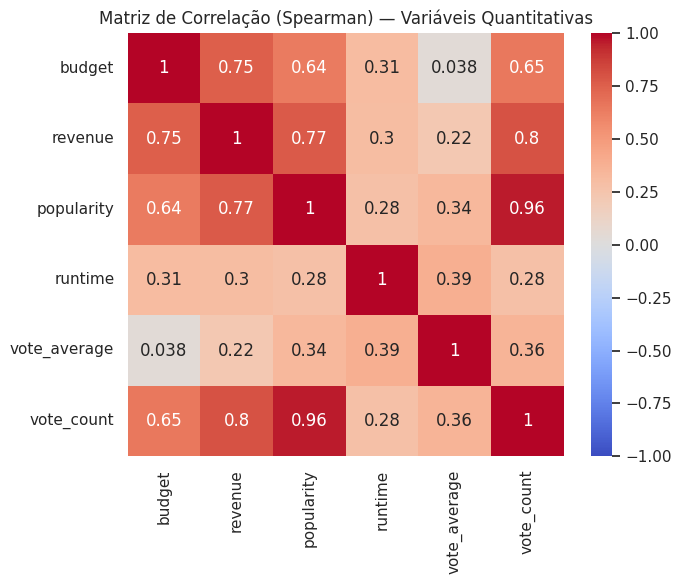

In [84]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()

**Como interpretar:**

*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*   |r| > 0.7 ~ forte.

`popularity` x `vote_count` (0,96) chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis — faz sentido, já que ambas medem "quanto o filme foi visto/comentado".

##### Correlograma

Text(0.5, 1.02, 'Correlograma: Dispersão × Correlação')

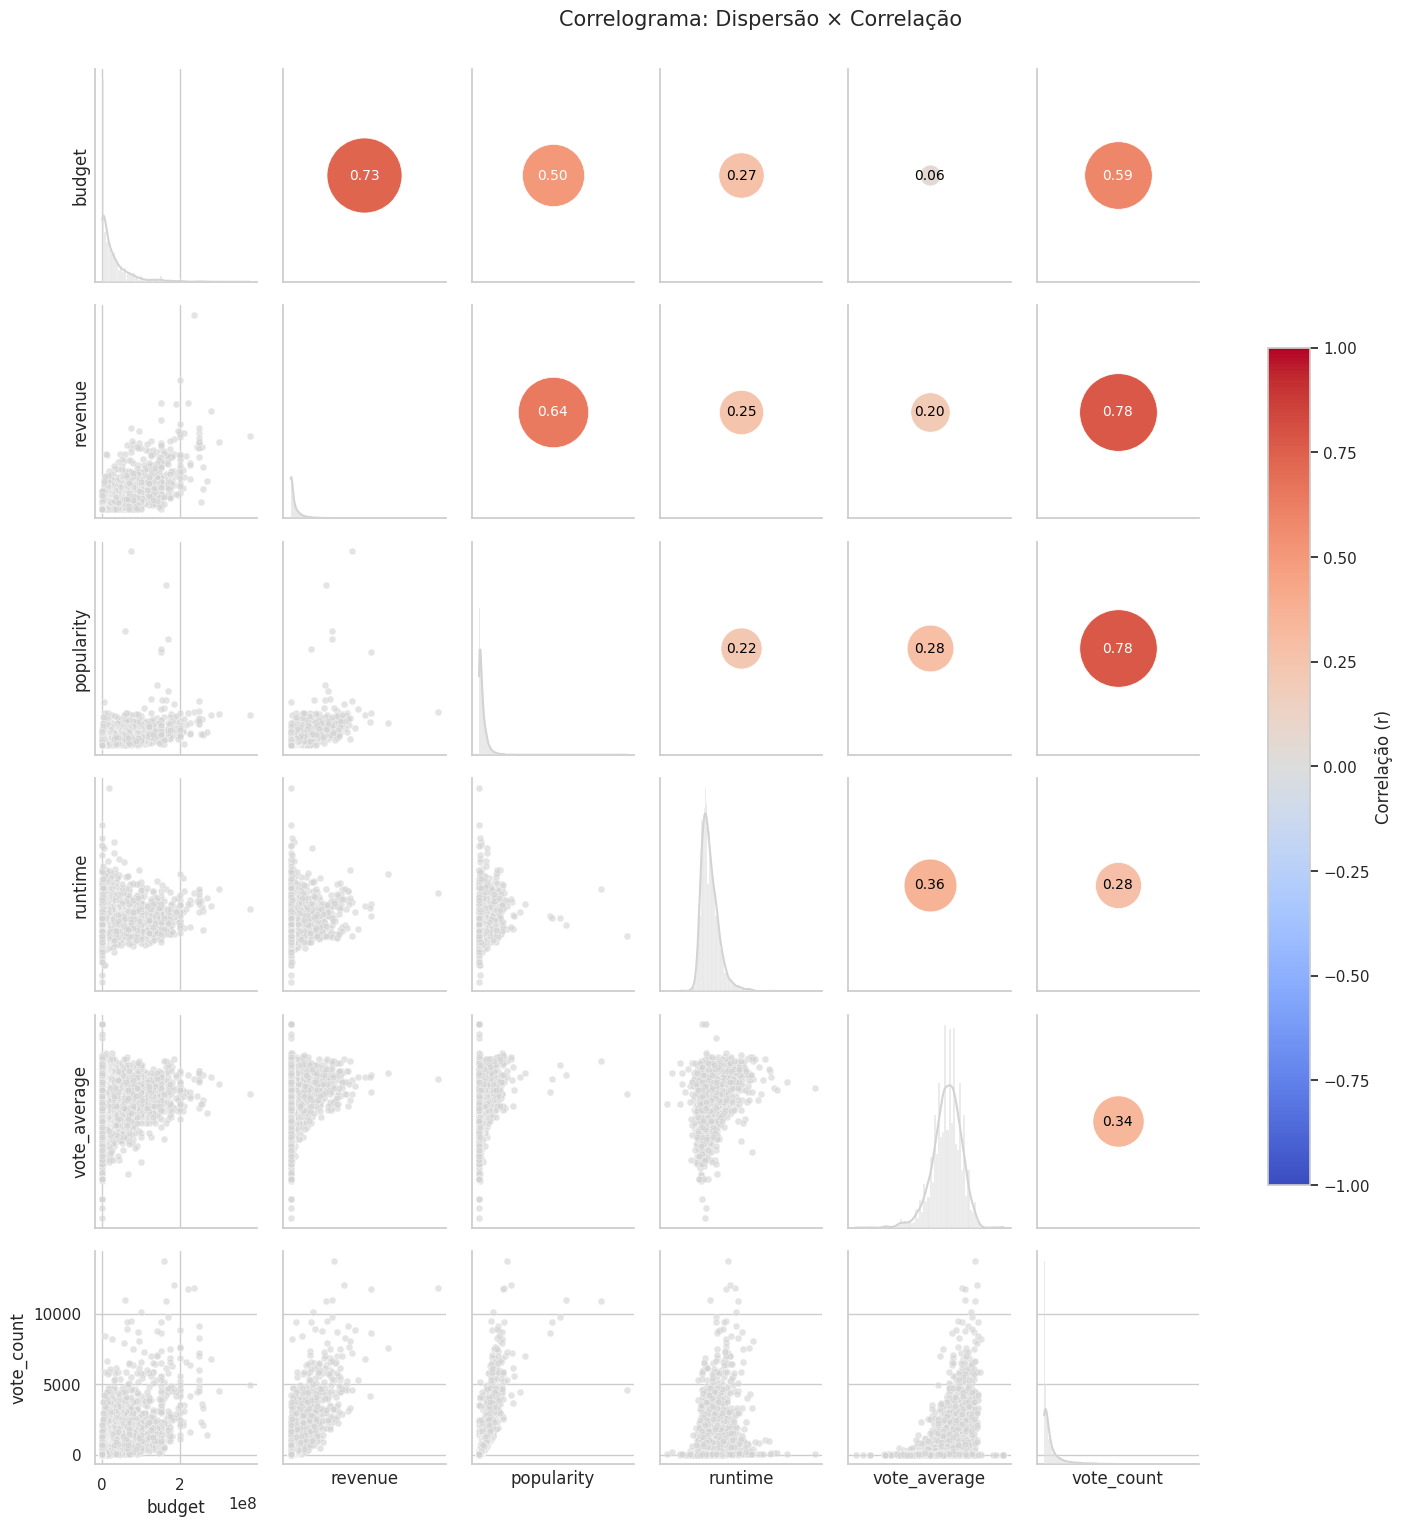

In [86]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    mask = ~(pd.isna(x) | pd.isna(y))
    x, y = x[mask], y[mask]
    r = np.corrcoef(x, y)[0, 1]
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,
        c=[r], cmap='coolwarm', vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

g = sns.PairGrid(df[VARS_QUANT], diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.6, s=25)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")

g.fig.suptitle("Correlograma: Dispersão × Correlação", y=1.02, fontsize=15)

## Síntese Final

### Principais Conclusões

1. **Dinheiro não compra nota, mas alcance sim.** `budget` foi a única variável quantitativa que não diferiu estatisticamente entre "Bem avaliado" e "Mal avaliado" (Mann-Whitney p≈0,22). Já `revenue`, `popularity` e `vote_count` diferiram fortemente — filmes bem avaliados tendem a ser mais vistos e mais rentáveis, mas isso não significa que gastar mais produz um filme melhor.

2. **Viés temporal forte na base.** A proporção de "Bem avaliado" cai de 85,3% em filmes pré-1970 pra 47,7% nos de 2010 (Qui² p≈2,5e-27). O mais provável é viés de sobrevivência: só os clássicos de décadas antigas continuam catalogados, enquanto a leva recente inclui produção "comum" ainda sem esse filtro do tempo — não necessariamente uma queda real de qualidade.

3. **Idioma original também se associa à nota, mas provavelmente por viés de curadoria.** Filmes em inglês (94% da base) têm proporção de bem avaliados menor (52,6%) que filmes em outros idiomas (61,5%-75,9%, Qui² p≈6e-9) — plausivelmente porque produções estrangeiras só entram nesse catálogo internacional quando já ganharam alguma visibilidade, uma seleção prévia de qualidade que o catálogo em inglês não tem.

4. **Qualidade dos dados exigiu tratamento antes de qualquer análise.** ~21% dos filmes tinham `budget` ou `revenue` zerados (não informados, não genuinamente zero) e 23 filmes tinham `runtime = 0` (erro de dado). Esses casos foram sinalizados/corrigidos antes da análise principal — ignorá-los teria distorcido a mediana usada para criar o próprio alvo.

5. **Nenhuma variável quantitativa é normal.** Todas rejeitaram o Shapiro-Wilk (Seção 3), então testes não-paramétricos (Spearman, Mann-Whitney, Kruskal-Wallis) foram usados como resultado principal em toda a análise bivariada, com os paramétricos mantidos só como contraste pedagógico.


### Declaração de Uso de IA

**Ferramenta utilizada:** Claude (Anthropic), via chat.

**Para o que foi aplicada:**
- Reformular trechos de discussão que eu já tinha escrito, deixando a redação mais clara.
- Tirar dúvidas sobre erros de execução no Colab (ex: `NameError` por kernel reiniciado, bug no correlograma com valores ausentes em `runtime`).
- Conferir se decisões que tomei ao longo da análise (ex: como tratar `budget`/`revenue` zerados, `runtime = 0`, definição do alvo `avaliacao`) faziam sentido pro dataset.

**O que foi aceito:** as reformulações de texto que fizeram sentido pra o que eu já queria dizer, e as explicações sobre a causa dos erros de execução.

**Escolhas próprias:** as decisões de análise em si (definição do alvo, tratamento de ausentes/outliers, escolha de variáveis pra cada teste) foram minhas — a IA serviu pra confirmar se faziam sentido, não pra decidir por mim.